In [ ]:
# 15. Implement a Feedforward Neural Network using two hidden Dense layers 
# to classify handwritten digits. Observe the effect of hidden layers on 
# model performance. 
# Use Dataset -- Handwritten MNIST 

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import mnist

In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


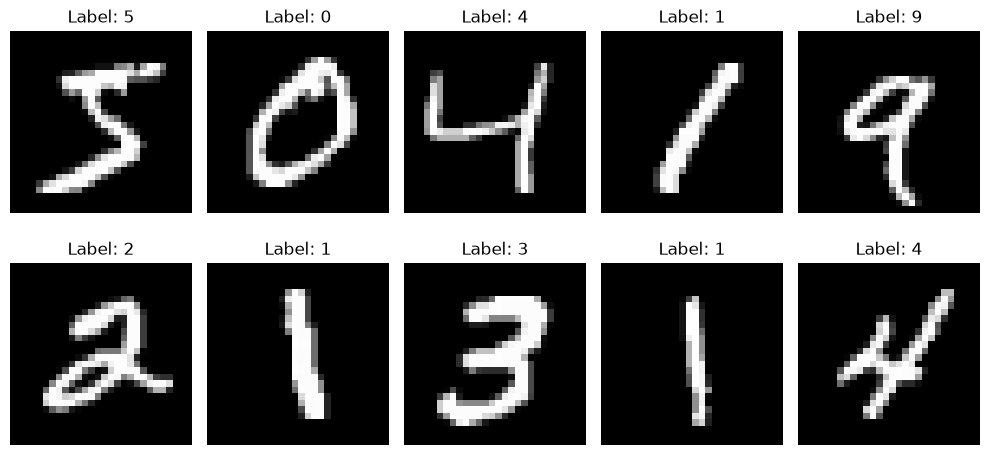

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Label: " + str(y_train[i]))
    plt.axis('off')

plt.tight_layout()
plt.show()

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)


In [5]:
model = Sequential([
    Flatten(input_shape=(28, 28)),

    Dense(128, activation='relu'),

    Dense(64, activation='relu'),

    Dense(10, activation='softmax')
])

model.summary()

C:\Users\prerna\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\reshaping\flatten.py:36: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9235 - loss: 0.2656 - val_accuracy: 0.9584 - val_loss: 0.1403
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9672 - loss: 0.1084 - val_accuracy: 0.9670 - val_loss: 0.1090
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9778 - loss: 0.0738 - val_accuracy: 0.9705 - val_loss: 0.1035
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.9842 - loss: 0.0526 - val_accuracy: 0.9703 - val_loss: 0.1049
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9879 - loss: 0.0380 - val_accuracy: 0.9721 - val_loss: 0.1033
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9892 - loss: 0.0323 - val_accuracy: 0.9716 - val_loss: 0.1204
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9916 - loss: 0.0258 - val_accuracy: 0.9716 - val_loss: 0.1208
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9920 - loss: 0.0233 

In [8]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9738 - loss: 0.1141
Test Loss: 0.11407265812158585
Test Accuracy: 97.3800003528595 %


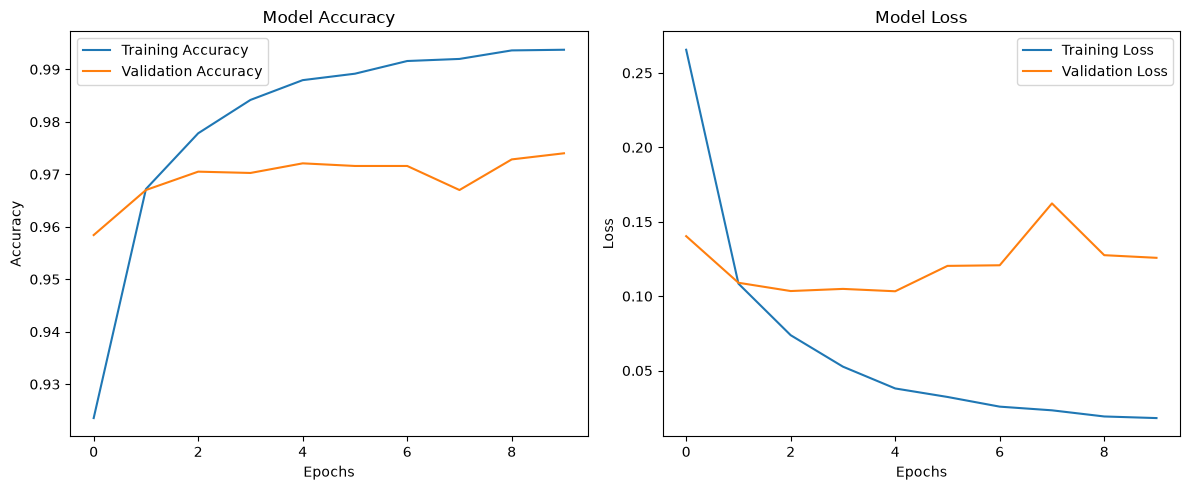

In [9]:
plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [10]:
predictions = model.predict(x_test[:10])

predicted_labels = np.argmax(predictions, axis=1)

print("Predicted digits:", predicted_labels)
print("Actual digits:   ", y_test[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
Predicted digits: [7 2 1 0 4 1 4 9 5 9]
Actual digits:    [7 2 1 0 4 1 4 9 5 9]


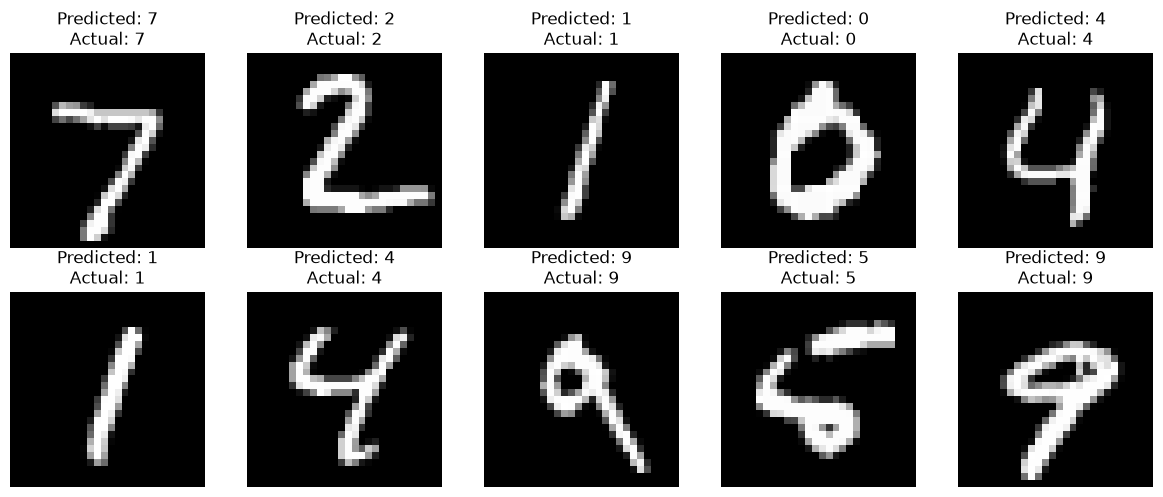

In [11]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')

    plt.title(
        f"Predicted: {predicted_labels[i]}\nActual: {y_test[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

In [12]:
def create_model(hidden_layers):

    model = Sequential()
    model.add(Flatten(input_shape=(28, 28)))

    for neurons in hidden_layers:
        model.add(Dense(neurons, activation='relu'))

    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


architectures = {
    "1 Hidden Layer": [128],
    "2 Hidden Layers": [128, 64],
    "3 Hidden Layers": [128, 64, 32]
}

results = {}

for name, layers in architectures.items():

    print("\nTraining", name)

    temp_model = create_model(layers)

    temp_model.fit(
        x_train,
        y_train,
        epochs=5,
        batch_size=32,
        validation_split=0.2,
        verbose=1
    )

    loss, accuracy = temp_model.evaluate(
        x_test, y_test, verbose=0
    )

    results[name] = accuracy * 100

    print(name, "Test Accuracy:", accuracy * 100)


Training 1 Hidden Layer
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9177 - loss: 0.2875 - val_accuracy: 0.9521 - val_loss: 0.1634
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9624 - loss: 0.1287 - val_accuracy: 0.9633 - val_loss: 0.1228
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9749 - loss: 0.0870 - val_accuracy: 0.9677 - val_loss: 0.1077
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9820 - loss: 0.0632 - val_accuracy: 0.9693 - val_loss: 0.1024
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9871 - loss: 0.0473 - val_accuracy: 0.9711 - val_loss: 0.1013
1 Hidden Layer Test Accuracy: 97.35999703407288

Training 2 Hidden Layers
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9214 - loss: 0.2668 - val_accuracy: 0.9577 - val_loss: 0.1429
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9657 - loss: 0.1131 - val_accuracy: 0.9667 - val_loss: 0.


Performance Comparison
1 Hidden Layer : 97.36 %
2 Hidden Layers : 97.47 %
3 Hidden Layers : 97.06 %


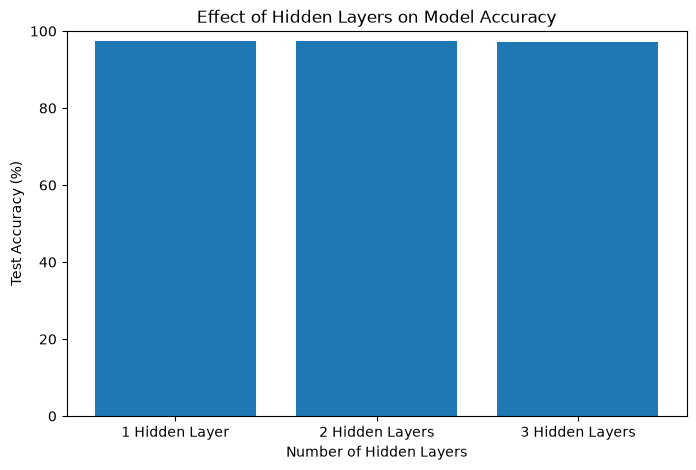

In [13]:
print("\nPerformance Comparison")

for name, accuracy in results.items():
    print(name, ":", round(accuracy, 2), "%")

plt.figure(figsize=(8, 5))

plt.bar(results.keys(), results.values())

plt.title("Effect of Hidden Layers on Model Accuracy")
plt.xlabel("Number of Hidden Layers")
plt.ylabel("Test Accuracy (%)")

plt.ylim(0, 100)
plt.show()